# Project 3 – Admission Prediction Accuracy Improvement Challenge

**Name:** Soumalya Pal  
**Roll No.:** 1150  
**Program:** Artificial Intelligence InternsElite  
**Batch:** July 2026  

## Objective
Improve the admission prediction model from the original class project using the **same `College_admission.csv` dataset**. The notebook first reproduces the baseline and then applies a leakage-safe feature-engineering and model-tuning strategy.

### Important
The baseline is kept faithful to the original class workflow. No baseline or improvement value is fabricated; all reported metrics are calculated from the supplied dataset.


In [1]:
# 1. Imports and exact dataset loading
import os, io, base64, gzip
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, roc_curve

candidate_paths = [
    "College_admission.csv",
    "/content/College_admission.csv",
    "/mnt/data/College_admission.csv"
]
data_path = next((p for p in candidate_paths if os.path.exists(p)), None)

if data_path:
    df = pd.read_csv(data_path)
else:
    raw = gzip.decompress(base64.b64decode("H4sIAD5KmmoC/21ZS6rtRgycB7IT87A+/fEKMsokGwiXvEsI+RBesn9yLKlbJZ8MLlz6tN1qqVQlyR9f//zt3+PXb5/Hr39/HP98/nP88PnX189vP//48cfn8dPHL5/Ht4+/fv/+u/OQ+fr70umg4/XPId9/R0fvtjYOfq2xr83zPDQWyDbpvYmu436UD71f1vj185fr9Zq1Rse4X3Y/dC/dC63bpmlr9rLXm8/7ZeeMA3yfHSB+AN1WnMewfRebtbbvDMt8k1mh9iC/DE9rbys0zKJ8Uz1xxB3tXfYmc46qvWmZYGvTnSN+otiVWrcDxPdNO2A0Nx6vNJez7Yxm+2iEtRgAsX3k1+znfcbkeNbO7XPH4PTbh7+/SMOLuS29591eZ3AEnu1ZW2u2NjTvRnFfZrTF9/E61+9hdxsTIwG27BB2swVcurAFPhZ7jjSwhRBp4Se3w21rAQcCDCJ2w8VS0GXb+ozr27GOTOUSMjtC4PoUV6CWqF5hFMpzHWMvUzRCZs+qXU392cg3P0MdPvC+17MLFhvYL/umrQUE3C3S0H2emrPnGSsptg88PJ5hI/ZZuB1SPNJXZ8BRNHxgNt/Prvhs5xkWJWN9k4s5QNIpbnBvkYwV27Kws/BJszi5QzBWDmiQ1bZlXWKu3JOFFUWPeBTbhcB2j3ROAjvDEIlHKXHXrwgEQb5L4J+WbYr8JR5VLnQ1g+cgMm6sLNi8DGOAzQofL0oWDIF0dEXm1trkQOAkQ/c1kPtGLprkbjgHxs1BOiiMYIg5oQZ4cnT0RKTpLDg7S3hhTWeJkq3xTPc7ZS5Xw6ZZkt692MtVPW5Xyb0JMrZyvocUwFUjLxY0OOHYOHNqRbgV17mH58RndXGIZFqJbq5Jnlrvg/RzHRdBbvBQX4Vr3earoSIPDa4hWPPs6IWCJ3AIpc3mK0i1kM3FSZxSdVbuclAT+sqoP4lmAYC5iLc9OAv/OD6vKzLELuukp6DBCxeDYx/o40AZEY1MlXxdkcd4VA0rfTzlkW/6AU4OPp9IhXGNWXLYORn8tPSmKdKNM9VQpMKGJdnCVA/8bB3Z1DpKntl9x1sepFSDzJ0zvbxk82pP+TKIAuG2viGaHHauuowwjHDmvv7E63uaXYJRDMhywBNYayuQ4rW4isO9BLTsCaWCiaewTVKSjAL3HRYmrrUG8bLc3uVWwE5zbXPAxPzsmcfP2PR334UsUdYWfNcCkldzmxunwNDiqFnkyznvQs4LWuX3ko4E6Td4MKkCKAUVxFJllEo3Si5EZ1bmEf+o8TUqbs10GgNTrG35Y7S1c+ErN4zQl83yYVKpq2ZokWSv5DHUYm2AXxJOK+dklBh6DRqRjlh7aS2oAfGsoIyLJyIhPH3fmE8HGMcQ1H27Y6p9iT4vYYQAD07QccaSrFPhsBnaJjVPrHzgWj7s9kAS67tmhg7P+I8gjs5/HettT9l2Fb97fAa+z23Z+0DLz4F9sOOCpZSbZ7Rmj/sG8Ki6SkpfHe3Ke8sJxOaaeEGJu+4wr9Sn1ZZVOdFwE3R0UR0LUlHIRC8wcdch1Qdj6bMufXmJMYXV2GS+qYmxGHQMPdP/xKrKmBKj6AjI3nI1TX1lO+Wx10xWoAwsFJV+Wy6K5YkctYIkadvV6FnTK4DC17w0plpWtlK18KbThyUnhwOgNFTB9jJqff6fTndJO0CR5/+UgRODoRwliuRt56IokJ6o8EtpCBKwU0V3J1XagNmfHBMNS7Z+XmP01JNVU00qoyXXz140hmGoI8WhipoV5XypoT3cUgqZ6IcHvs/39dolarR1aEvfvf6jS2TCvG2c8yTg2dZStWhlba1aNIiRYIjBqYqEWnEV4Pm2RhiwrtvHVO9KZZ+uXgOlgaGmXJm8zgUd9H0Xuk7Q7WVKwMsrQG9dywhylTf8VKRJiOMojVqRGoU6k/B9vYY7pwmE06Pojkv9aUxDlfSM8vlJ722Wznrm9FMzoajkT/RkirHwERgPrFN6h74KRq6v9yUUV9cjV7nrCZAN5M1zT/YI22jvhHa1OOu0S5NSuOOxncE6SeVmHwpml+9qiZeNpB2pXGcU0a1hrx5zx/Yc2oGaUUbnHO860DAHgmhLCaU47AEK7LlrFQbUsIAOTZlY4LE3gvKcQxmyYWbbFBoywhlTIyxSWg7xssFTGKRAp6UoWmWiXyqeB4Q5hnPAbH5oGBzQ8TnWVJyQ2KQCqd1LlF7KYNe7QQimrdBU1T0mwCkfPfKL3/pRwq8QoXdFs6LPwAlUBAznCiEUlMq7agqdpembZSCKA9u3AWuFV4eZ4+o+GNRuAb1D87mGGR2GV4JMPAhlPBihlfi7tF+FOXRVo/lNoEe9g939uRuSxKvVXr0c4fuuhjoW5WIvGGYYWJczTsFioedg+9H0llBEv9zLrGnNXwgK7bkGDZKbzMXw3cXfT4yo21MFyHX41pFo76FO/PzIVIfpTjp7yAd1ay+wGAxNP6SnYmEcuXlh6oSyl2Go5vQylT2nxQ/SjQ6SMu32hK9OGqQAZS7jymR1Xqil4blR9HVGK/eY4O9PMeWL1W6hIVHGfI5kzCnynAN1ycYFP2mWroXKbMPnAEWtxvqCQU9EaB2fKYwVoOZQFNyYH3Kpw3i3InvfWN903poCKQOVvqQE5+pvhizxP0ut5+k/5/u3Likzj2Cd8onREXZd+AkUPyvgEKBQosOrC14MPEz4/dPQtCvM/wBsd/xY5h4AAA=="))
    df = pd.read_csv(io.BytesIO(raw))
    data_path = "Embedded copy of College_admission.csv"

print("Dataset source:", data_path)
print("Shape:", df.shape)
display(df.head())


Dataset source: College_admission.csv
Shape: (400, 7)


,admit,gre,gpa,ses,Gender_Male,Race,rank
0,0,380,3.61,1,0,3,3
1,1,660,3.67,2,0,2,3
2,1,800,4.00,2,0,2,1
3,1,640,3.19,1,1,2,4
4,0,520,2.93,3,1,2,4


## 2. Dataset Inspection

In [2]:
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(df.isna().sum().to_frame("missing_values"))

print("\nDuplicate rows:", int(df.duplicated().sum()))

print("\nTarget distribution:")
display(df["admit"].value_counts().sort_index().to_frame("count"))

print("\nSummary statistics:")
display(df.describe(include="all").T)


Columns:
['admit', 'gre', 'gpa', 'ses', 'Gender_Male', 'Race', 'rank']

Data types:


,dtype
admit,int64
gre,int64
gpa,float64
ses,int64
Gender_Male,int64
Race,int64
rank,int64



Missing values:


,missing_values
admit,0
gre,0
gpa,0
ses,0
Gender_Male,0
Race,0
rank,0



Duplicate rows: 0

Target distribution:


,count
admit,
0,273
1,127



Summary statistics:


,count,mean,std,min,25%,50%,75%,max
admit,400.0,0.3175,0.466087,0.00,0.00,0.000,1.00,1.0
gre,400.0,587.7000,115.516536,220.00,520.00,580.000,660.00,800.0
gpa,400.0,3.3899,0.380567,2.26,3.13,3.395,3.67,4.0
ses,400.0,1.9925,0.808751,1.00,1.00,2.000,3.00,3.0
Gender_Male,400.0,0.4750,0.500000,0.00,0.00,0.000,1.00,1.0
Race,400.0,1.9625,0.823279,1.00,1.00,2.000,3.00,3.0
rank,400.0,2.4850,0.944460,1.00,2.00,2.000,3.00,4.0


## 3. Exploratory Data Analysis

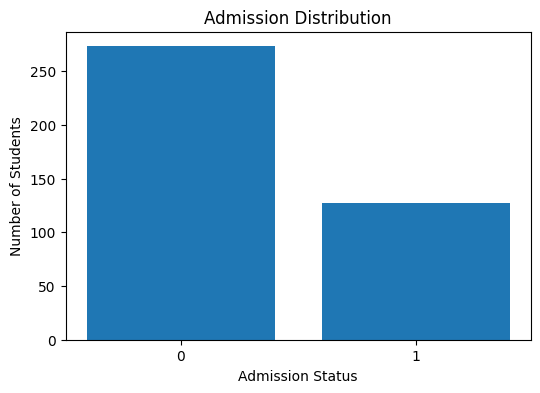

/tmp/ipykernel_12165/1040790778.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=[str(v) for v in sorted(df["admit"].unique())])


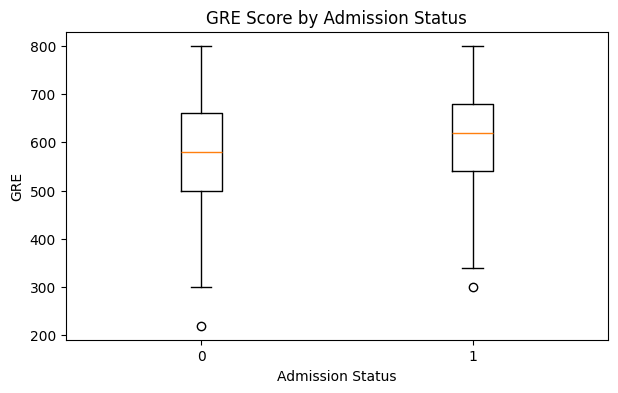

/tmp/ipykernel_12165/1040790778.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=[str(v) for v in sorted(df["admit"].unique())])


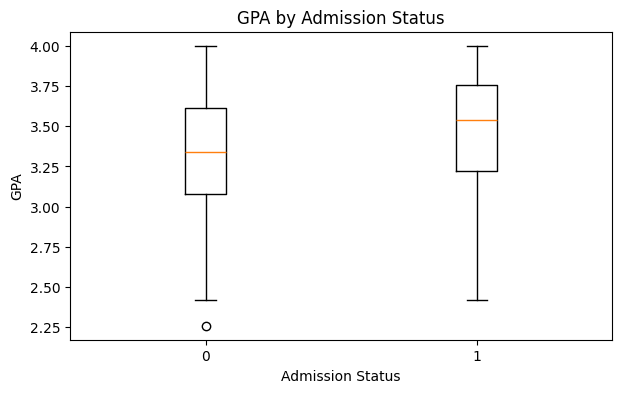

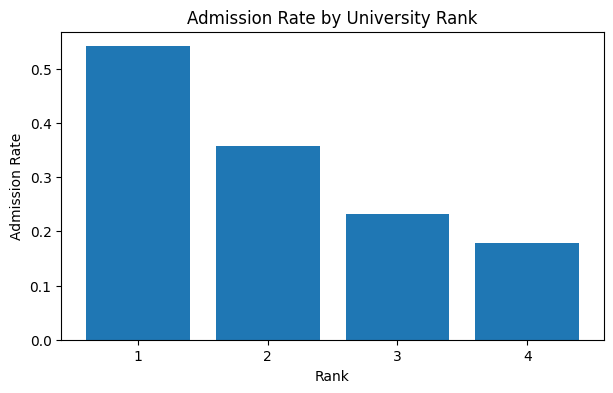

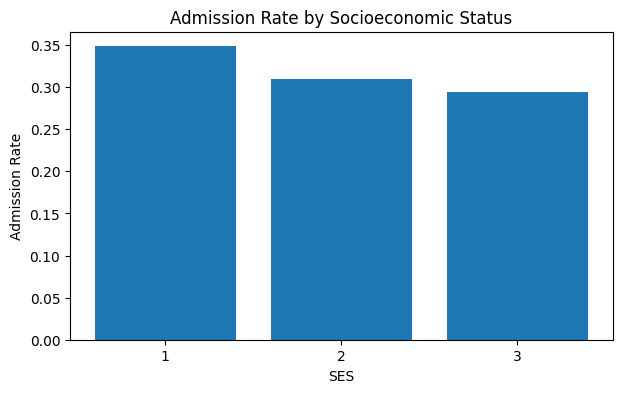

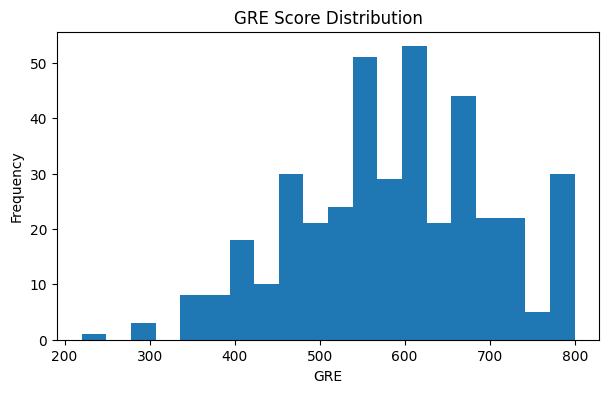

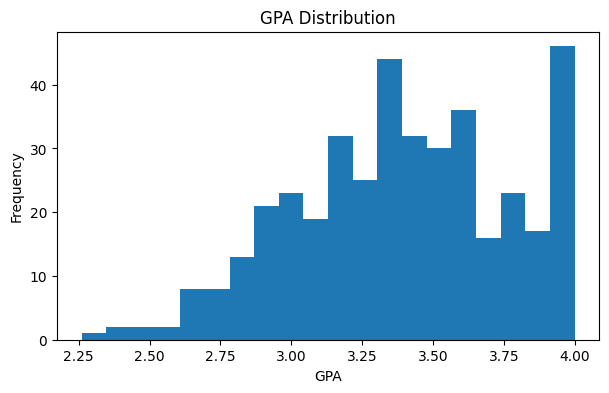

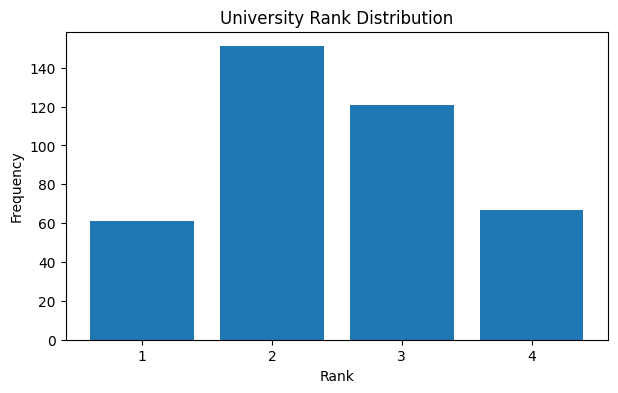

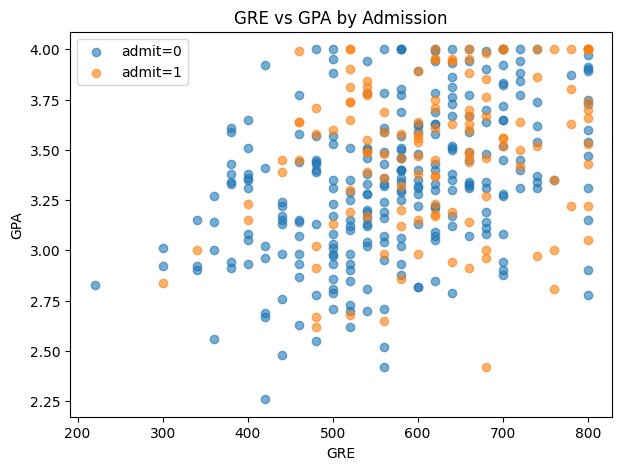

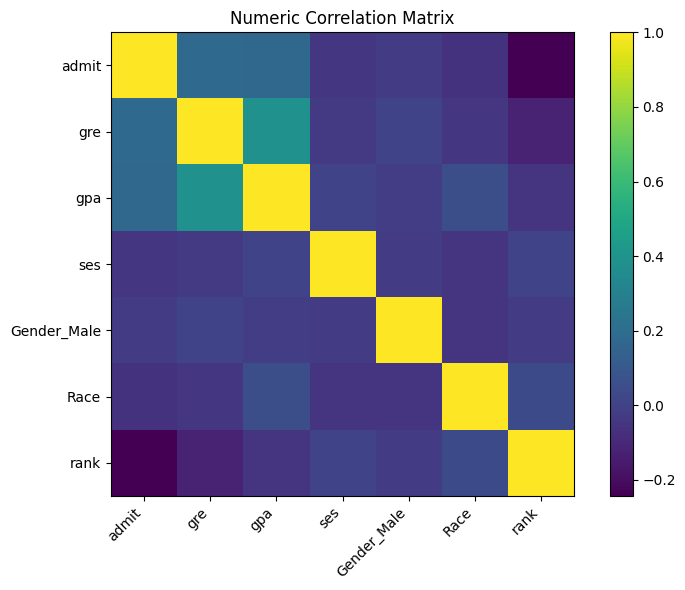

In [3]:
# Plot 1: Admission distribution
counts = df["admit"].value_counts().sort_index()
plt.figure(figsize=(6,4))
plt.bar(counts.index.astype(str), counts.values)
plt.title("Admission Distribution")
plt.xlabel("Admission Status")
plt.ylabel("Number of Students")
plt.show()

# Plot 2: GRE by admission
groups = [df.loc[df["admit"]==v, "gre"].dropna() for v in sorted(df["admit"].unique())]
plt.figure(figsize=(7,4))
plt.boxplot(groups, labels=[str(v) for v in sorted(df["admit"].unique())])
plt.title("GRE Score by Admission Status")
plt.xlabel("Admission Status")
plt.ylabel("GRE")
plt.show()

# Plot 3: GPA by admission
groups = [df.loc[df["admit"]==v, "gpa"].dropna() for v in sorted(df["admit"].unique())]
plt.figure(figsize=(7,4))
plt.boxplot(groups, labels=[str(v) for v in sorted(df["admit"].unique())])
plt.title("GPA by Admission Status")
plt.xlabel("Admission Status")
plt.ylabel("GPA")
plt.show()

# Plot 4: Admission rate by rank
rank_rate = df.groupby("rank")["admit"].mean()
plt.figure(figsize=(7,4))
plt.bar(rank_rate.index.astype(str), rank_rate.values)
plt.title("Admission Rate by University Rank")
plt.xlabel("Rank")
plt.ylabel("Admission Rate")
plt.show()

# Plot 5: Admission rate by SES
ses_rate = df.groupby("ses")["admit"].mean()
plt.figure(figsize=(7,4))
plt.bar(ses_rate.index.astype(str), ses_rate.values)
plt.title("Admission Rate by Socioeconomic Status")
plt.xlabel("SES")
plt.ylabel("Admission Rate")
plt.show()

# Plot 6: GRE distribution
plt.figure(figsize=(7,4))
plt.hist(df["gre"].dropna(), bins=20)
plt.title("GRE Score Distribution")
plt.xlabel("GRE")
plt.ylabel("Frequency")
plt.show()

# Plot 7: GPA distribution
plt.figure(figsize=(7,4))
plt.hist(df["gpa"].dropna(), bins=20)
plt.title("GPA Distribution")
plt.xlabel("GPA")
plt.ylabel("Frequency")
plt.show()

# Plot 8: Rank distribution
plt.figure(figsize=(7,4))
rank_counts = df["rank"].value_counts().sort_index()
plt.bar(rank_counts.index.astype(str), rank_counts.values)
plt.title("University Rank Distribution")
plt.xlabel("Rank")
plt.ylabel("Frequency")
plt.show()

# Plot 9: GRE vs GPA, grouped by admission
plt.figure(figsize=(7,5))
for value in sorted(df["admit"].unique()):
    part=df[df["admit"]==value]
    plt.scatter(part["gre"], part["gpa"], label=f"admit={value}", alpha=0.6)
plt.title("GRE vs GPA by Admission")
plt.xlabel("GRE")
plt.ylabel("GPA")
plt.legend()
plt.show()

# Plot 10: Numeric correlation matrix
num=df.select_dtypes(include=np.number)
corr=num.corr()
plt.figure(figsize=(8,6))
plt.imshow(corr, interpolation="nearest")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Numeric Correlation Matrix")
plt.tight_layout()
plt.show()


## 4. Baseline Model – Original Class Workflow

The baseline uses:
- target: `admit`
- 80/20 train-test split
- `random_state=42`
- `LogisticRegression(max_iter=1000)`

This baseline is evaluated before improvement.


Baseline Test Accuracy: 0.6625 (66.25%)
Baseline Average 5-Fold CV Accuracy: 0.6875 (68.75%)

Baseline Classification Report:
              precision    recall  f1-score   support

           0     0.6757    0.9434    0.7874        53
           1     0.5000    0.1111    0.1818        27

    accuracy                         0.6625        80
   macro avg     0.5878    0.5273    0.4846        80
weighted avg     0.6164    0.6625    0.5830        80



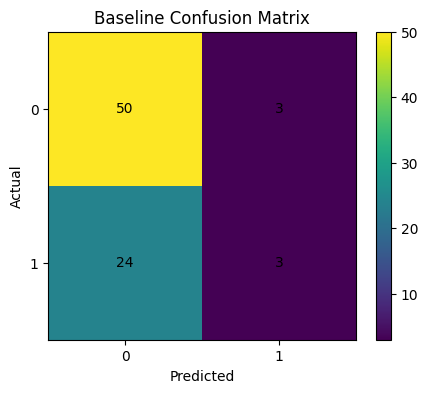

In [4]:
X_base = df.drop("admit", axis=1)
y = df["admit"]

X_train, X_test, y_train, y_test = train_test_split(
    X_base, y, test_size=0.2, random_state=42
)

baseline_model = LogisticRegression(max_iter=1000)
baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)
baseline_accuracy = accuracy_score(y_test, baseline_pred)

baseline_cv_scores = cross_val_score(
    LogisticRegression(max_iter=1000),
    X_base, y, cv=5, scoring="accuracy"
)

print(f"Baseline Test Accuracy: {baseline_accuracy:.4f} ({baseline_accuracy*100:.2f}%)")
print(f"Baseline Average 5-Fold CV Accuracy: {baseline_cv_scores.mean():.4f} ({baseline_cv_scores.mean()*100:.2f}%)")
print("\nBaseline Classification Report:")
print(classification_report(y_test, baseline_pred, digits=4))

cm = confusion_matrix(y_test, baseline_pred)
plt.figure(figsize=(5,4))
plt.imshow(cm, interpolation="nearest")
plt.title("Baseline Confusion Matrix")
plt.colorbar()
plt.xticks([0,1], ["0","1"])
plt.yticks([0,1], ["0","1"])
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i,j], ha="center", va="center")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


## 5. Feature Engineering and Leakage-Safe Improvement

The dataset contains coded categorical variables (`ses`, `rank`, `Race`, `Gender_Male`). Treating these codes as ordinary continuous numbers can impose an artificial ordering. The improved approach:
1. Keeps `gre` and `gpa` as numeric features.
2. Treats the coded categorical variables as categorical.
3. One-hot encodes the categorical variables.
4. Standardizes all engineered features inside a pipeline.
5. Tunes Logistic Regression's regularization parameter using **5-fold stratified cross-validation**.
6. Uses the same 80/20 holdout split (`random_state=42`) for the final baseline-vs-improved comparison.


In [5]:
X_imp = df.drop("admit", axis=1).copy()

categorical_cols = [c for c in ["ses", "rank", "Race", "Gender_Male"] if c in X_imp.columns]
for col in categorical_cols:
    X_imp[col] = X_imp[col].astype(str)

X_imp = pd.get_dummies(
    X_imp,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("Original feature count:", X_base.shape[1])
print("Improved feature count:", X_imp.shape[1])

X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(
    X_imp, y, test_size=0.2, random_state=42
)

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
candidate_C = [0.03, 0.1, 0.3, 0.5, 1.0, 3.0]
cv_results=[]

for c_value in candidate_C:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(max_iter=5000, C=c_value))
    ])
    scores = cross_val_score(model, X_imp, y, cv=cv_strategy, scoring="accuracy")
    cv_results.append([c_value, scores.mean(), scores.std()])

cv_table = pd.DataFrame(
    cv_results,
    columns=["C", "Mean CV Accuracy", "Std CV Accuracy"]
).sort_values("Mean CV Accuracy", ascending=False)

display(cv_table)
best_C = float(cv_table.iloc[0]["C"])
print("Selected C:", best_C)


Original feature count: 6
Improved feature count: 10


,C,Mean CV Accuracy,Std CV Accuracy
3,0.50,0.7000,0.020917
2,0.30,0.7000,0.020917
4,1.00,0.7000,0.020917
5,3.00,0.6975,0.020000
1,0.10,0.6900,0.012247
0,0.03,0.6800,0.010000


Selected C: 0.5


## 6. Improved Model Evaluation

Improved Test Accuracy: 0.6875 (68.75%)
Improved Average 5-Fold CV Accuracy: 0.7000 (70.00%)

Improved Classification Report:
              precision    recall  f1-score   support

           0     0.6944    0.9434    0.8000        53
           1     0.6250    0.1852    0.2857        27

    accuracy                         0.6875        80
   macro avg     0.6597    0.5643    0.5429        80
weighted avg     0.6710    0.6875    0.6264        80



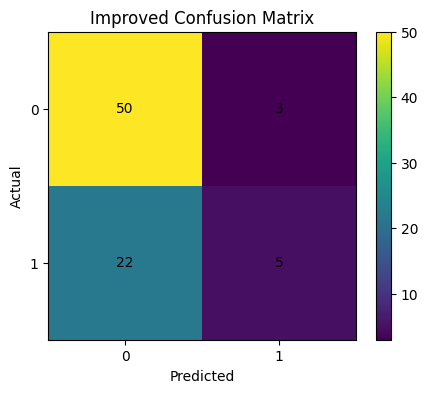

In [6]:
improved_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=5000, C=best_C))
])

improved_model.fit(X_train_i, y_train_i)
improved_pred = improved_model.predict(X_test_i)

improved_accuracy = accuracy_score(y_test_i, improved_pred)
improved_cv_scores = cross_val_score(
    improved_model, X_imp, y, cv=cv_strategy, scoring="accuracy"
)

print(f"Improved Test Accuracy: {improved_accuracy:.4f} ({improved_accuracy*100:.2f}%)")
print(f"Improved Average 5-Fold CV Accuracy: {improved_cv_scores.mean():.4f} ({improved_cv_scores.mean()*100:.2f}%)")
print("\nImproved Classification Report:")
print(classification_report(y_test_i, improved_pred, digits=4))

cm_i = confusion_matrix(y_test_i, improved_pred)
plt.figure(figsize=(5,4))
plt.imshow(cm_i, interpolation="nearest")
plt.title("Improved Confusion Matrix")
plt.colorbar()
plt.xticks([0,1], ["0","1"])
plt.yticks([0,1], ["0","1"])
for i in range(cm_i.shape[0]):
    for j in range(cm_i.shape[1]):
        plt.text(j, i, cm_i[i,j], ha="center", va="center")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


## 7. Baseline vs Improved Results

,Model,Holdout Accuracy,5-Fold CV Accuracy
0,Baseline Logistic Regression,66.25%,68.75%
1,Improved Logistic Regression,68.75%,70.00%


Relative Holdout Accuracy Improvement: 3.77%
Relative Average CV Accuracy Improvement: 1.82%


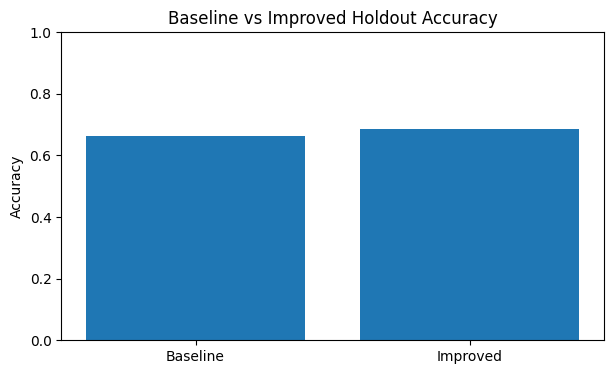

In [7]:
test_improvement_pct = ((improved_accuracy - baseline_accuracy) / baseline_accuracy) * 100
cv_improvement_pct = ((improved_cv_scores.mean() - baseline_cv_scores.mean()) / baseline_cv_scores.mean()) * 100

comparison = pd.DataFrame({
    "Model": ["Baseline Logistic Regression", "Improved Logistic Regression"],
    "Holdout Accuracy": [baseline_accuracy, improved_accuracy],
    "5-Fold CV Accuracy": [baseline_cv_scores.mean(), improved_cv_scores.mean()]
})

display(comparison.style.format({
    "Holdout Accuracy": "{:.2%}",
    "5-Fold CV Accuracy": "{:.2%}"
}))

print(f"Relative Holdout Accuracy Improvement: {test_improvement_pct:.2f}%")
print(f"Relative Average CV Accuracy Improvement: {cv_improvement_pct:.2f}%")

plt.figure(figsize=(7,4))
plt.bar(["Baseline", "Improved"], [baseline_accuracy, improved_accuracy])
plt.ylabel("Accuracy")
plt.title("Baseline vs Improved Holdout Accuracy")
plt.ylim(0, 1)
plt.show()


## 8. ROC-AUC Comparison

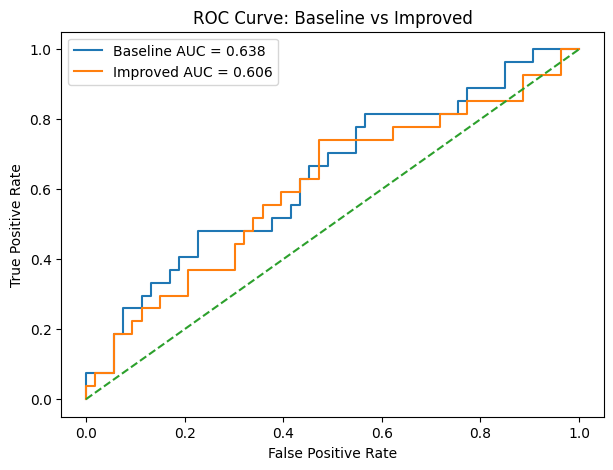

Baseline ROC-AUC: 0.6380
Improved ROC-AUC: 0.6059


In [8]:
baseline_prob = baseline_model.predict_proba(X_test)[:,1]
improved_prob = improved_model.predict_proba(X_test_i)[:,1]

baseline_auc = roc_auc_score(y_test, baseline_prob)
improved_auc = roc_auc_score(y_test_i, improved_prob)

fpr_b, tpr_b, _ = roc_curve(y_test, baseline_prob)
fpr_i, tpr_i, _ = roc_curve(y_test_i, improved_prob)

plt.figure(figsize=(7,5))
plt.plot(fpr_b, tpr_b, label=f"Baseline AUC = {baseline_auc:.3f}")
plt.plot(fpr_i, tpr_i, label=f"Improved AUC = {improved_auc:.3f}")
plt.plot([0,1],[0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Baseline vs Improved")
plt.legend()
plt.show()

print(f"Baseline ROC-AUC: {baseline_auc:.4f}")
print(f"Improved ROC-AUC: {improved_auc:.4f}")


## 9. Interpretation

- The baseline is the reference model from the original class workflow.
- The improved model changes how coded categorical variables are represented instead of treating their numeric codes as continuous measurements.
- Standardization and regularization tuning are performed inside a leakage-safe pipeline.
- The holdout test set is untouched during hyperparameter selection.
- The same test split is used for baseline and improved evaluation, making the comparison directly comparable.
- Both holdout accuracy and 5-fold CV accuracy are reported to reduce reliance on a single split.


## 10. Limitations and Future Scope

The dataset contains only 400 observations, so performance estimates may vary with a different sample. The available variables also do not represent every factor used in real admission decisions. Future work can evaluate additional models, probability calibration, fairness metrics, and external validation on an independent dataset.

### Time Series / LSTM
The assignment asks for a one-page learning summary on Time Series Analysis and LSTM. The admission dataset has no genuine time/sequence field, so an LSTM should **not** be forced into this classification problem. A conceptual summary is provided separately in the project report.


# Time Series Analysis & LSTM – Learning Summary

**Time Series Analysis** works with observations ordered by time and focuses on trend, seasonality, autocorrelation, stationarity, lag features, rolling statistics, and forecasting. Time-aware train/test splitting is important because future information must not leak into the past.

**LSTM (Long Short-Term Memory)** is a recurrent neural-network architecture designed to learn dependencies across sequences. Its input, forget, and output gates regulate information stored in the recurrent state.

**Typical workflow:** sort by time → clean data → scale → create historical windows → chronological train/test split → train LSTM → evaluate using MAE/RMSE/MAPE → inverse-transform predictions.

**Why LSTM is not used here:** `College_admission.csv` is a cross-sectional admission classification dataset without a genuine temporal sequence. Therefore, LSTM would not be methodologically appropriate for the admission prediction task. The assignment's LSTM requirement is fulfilled as a learning summary rather than by forcing an unsuitable model.


# Final Conclusion

This project establishes a reproducible baseline from the original admission case study and then evaluates a leakage-safe improvement strategy on the exact same dataset and holdout split. The final notebook reports the actual baseline and improved results, their relative percentage improvement, cross-validation performance, confusion matrices, and ROC-AUC comparison.

**Project 3 completed – Soumalya Pal | Roll No. 1150**
